ДЗ #1
Найти и согласовать со мной датасет.
Обучить как минимум 2 разных архитектуры сетей, использовать разобранные на занятии техники:
- Итеративная аугментация
- Итеративная разморозка слоев с адаптивным lr
- Псевдолейблинг

Я решил использовать модели DINO v3 () и ConvNeXt V2 Tiny (). Однако, мне не предоставили доступ к DINOv3, поэтому я решил использовать DINOv2 
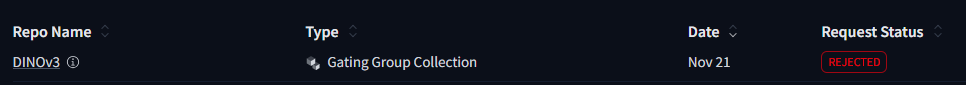

У случайного классификатора 10 классов accuracy около 0.10.
В [официальной таблице Imagewoof](https://github.com/fastai/imagenette#imagewoof-leaderboard) есть 87.2% при 128 px и 200 эпохах обучения с нуля. Для предобученных моделей ожидаем примерно 0.80–0.95. Порог 0.60 в коде обнаруживает только явно подозрительное качество.

Импорт библиотек

In [1]:
import gc
import random
import tarfile
from importlib.metadata import version
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from transformers import (
    AutoImageProcessor,
    AutoModel,
    AutoModelForImageClassification,
)

Основные настройки: размеры изображений и батчей, число эпох и параметры обучения, одинаковый seed

In [2]:
seed = 42
image_size = 224
resize_size = 256
batch_size = 32
num_workers = 2
stage_epochs = 3
extra_epochs = 2
pseudo_rounds = 2
validation_fraction = 0.20
labeled_fraction = 0.30
pseudo_threshold = 0.95
pseudo_limit = 100
backbone_lr = 0.00001
weight_decay = 0.01

output_dir: Path = Path("/kaggle/working/hw1")
data_parent: Path = Path("/tmp/imagewoof_data")
checkpoint_dir: Path = output_dir / "checkpoints"
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint_dir.mkdir(parents=True, exist_ok=True)

model_specs: dict = {
    "dinov2": {
        "model_id": "facebook/dinov2-small",
        "revision": "ed25f3a31f01632728cabb09d1542f84ab7b0056",
    },
    "convnextv2": {
        "model_id": "facebook/convnextv2-tiny-22k-224",
        "revision": "9cba4896e97bb86b1eb609e482a2149d84f345bc",
    },
}
training_stages: list[dict] = [
    {"unfreeze": 0.00, "augmentation": "weak", "head_lr": 0.001},
    {"unfreeze": 0.25, "augmentation": "medium", "head_lr": 0.0003},
    {"unfreeze": 0.50, "augmentation": "strong", "head_lr": 0.0001},
]
extra_stages: list[dict] = [training_stages[-1]] * pseudo_rounds
if not torch.cuda.is_available():
    raise RuntimeError("Enable GPU for training.")
device: torch.device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))


def set_seed(value: int) -> None:
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)


set_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

GPU: Tesla T4


Загружаем Imagewoof, распаковываем архив и проверяем количество изображений. Данные хранятся во временной папке

In [3]:
download_dir: Path = Path(kagglehub.dataset_download(
    "jhoward/imagewoof-160-px/versions/1"
))
archive_path: Path = download_dir / "imagewoof-160.tgz"
data_parent.mkdir(parents=True, exist_ok=True)
with tarfile.open(archive_path, "r:gz") as archive:
    archive.extractall(path=data_parent, filter="data")

data_dir: Path = data_parent / "imagewoof-160"
train_dataset: datasets.ImageFolder = datasets.ImageFolder(
    data_dir / "train"
)
test_dataset: datasets.ImageFolder = datasets.ImageFolder(data_dir / "val")
assert train_dataset.class_to_idx == test_dataset.class_to_idx
class_names: list[str] = [
    "Shih-Tzu", "Rhodesian ridgeback", "Beagle", "English foxhound",
    "Australian terrier", "Border terrier", "Golden retriever",
    "Old English sheepdog", "Samoyed", "Dingo",
]
num_classes = len(class_names)
assert len(train_dataset.classes) == num_classes
print("Train images:", len(train_dataset))
print("Test images:", len(test_dataset))
display(pd.DataFrame({"class_id": range(num_classes), "breed": class_names}))

Train images: 12454
Test images: 500


,class_id,breed
0,0,Shih-Tzu
1,1,Rhodesian ridgeback
2,2,Beagle
3,3,English foxhound
4,4,Australian terrier
5,5,Border terrier
6,6,Golden retriever
7,7,Old English sheepdog
8,8,Samoyed
9,9,Dingo


Делим исходный тренировочный сет на размеченные изображения, изображения со скрытыми метками и валидационную часть

In [4]:
all_images: pd.DataFrame = pd.DataFrame(
    train_dataset.samples, columns=["path", "label"]
)
train_images, validation_images = train_test_split(
    all_images,
    test_size=validation_fraction,
    stratify=all_images["label"],
    random_state=seed,
)
labeled_images, unlabeled_images = train_test_split(
    train_images,
    train_size=labeled_fraction,
    stratify=train_images["label"],
    random_state=seed,
)
unlabeled_images = unlabeled_images.copy()
unlabeled_images["label"] = -1
test_images: pd.DataFrame = pd.DataFrame(
    test_dataset.samples, columns=["path", "label"]
)
splits: dict[str, pd.DataFrame] = {
    "labeled": labeled_images,
    "unlabeled": unlabeled_images,
    "validation": validation_images,
    "test": test_images,
}
sizes: list[dict] = []
for name, table in splits.items():
    table = table.reset_index(drop=True)
    splits[name] = table
    table.to_csv(output_dir / f"{name}.csv", index=False)
    sizes.append({"split": name, "images": len(table)})
display(pd.DataFrame(sizes))
train_steps = len(splits["labeled"]) // batch_size
assert train_steps > 0
packages: list[str] = ["torch", "torchvision", "transformers", "kagglehub"]
versions: pd.DataFrame = pd.DataFrame({
    "package": packages,
    "version": [version(package) for package in packages],
})
versions.to_csv(output_dir / "versions.csv", index=False)

,split,images
0,labeled,2988
1,unlabeled,6975
2,validation,2491
3,test,500


Создаем уровни аугментации: weak, medium и strong. Для проверки качества используются только изменение размера, центральное кадрирование и нормализация конкретной модели

In [5]:
def train_transform(
    mean: list[float], std: list[float], strength: str
) -> transforms.Compose:
    steps: list = [
        transforms.RandomResizedCrop(image_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
    ]
    if strength == "medium":
        steps.append(transforms.ColorJitter(brightness=0.2, contrast=0.2))
    elif strength == "strong":
        steps.append(transforms.RandAugment(num_ops=2, magnitude=8))
    steps.append(transforms.ToTensor())
    steps.append(transforms.Normalize(mean=mean, std=std))
    return transforms.Compose(steps)


def eval_transform(
    mean: list[float], std: list[float]
) -> transforms.Compose:
    return transforms.Compose([
        transforms.Resize(resize_size),
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

In [6]:
class ImageDataset(Dataset):
    def __init__(self, table: pd.DataFrame,
                 transform: transforms.Compose) -> None:
        self.table: pd.DataFrame = table.reset_index(drop=True)
        self.transform: transforms.Compose = transform

    def __len__(self) -> int:
        return len(self.table)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:
        row = self.table.iloc[index]
        with Image.open(row["path"]) as image:
            image = image.convert("RGB")
            tensor: torch.Tensor = self.transform(image)
        return tensor, int(row["label"])


def make_loader(
    table: pd.DataFrame, transform: transforms.Compose,
    training: bool = False, epoch: int = 0,
) -> DataLoader:
    dataset: ImageDataset = ImageDataset(table, transform)
    generator: torch.Generator = torch.Generator()
    generator.manual_seed(seed + epoch)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=training,
        drop_last=training,
        num_workers=num_workers,
        generator=generator,
    )

Загружаем открытые веса DINOv2 или ConvNeXt V2 и добавляем линейный классификатор на 10 пород. Значения нормализации берем из настроек выбранной модели

In [7]:
class Classifier(nn.Module):
    def __init__(self, backbone: nn.Module, blocks: list[nn.Module],
                 feature_size: int) -> None:
        super().__init__()
        self.backbone: nn.Module = backbone
        self.head: nn.Linear = nn.Linear(feature_size, num_classes)
        self.blocks: list[nn.Module] = blocks

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        features: torch.Tensor = self.backbone(images).pooler_output
        logits: torch.Tensor = self.head(features)
        return logits


def make_model(
    architecture: str,
) -> tuple[Classifier, list[float], list[float]]:
    model_id = model_specs[architecture]["model_id"]
    revision = model_specs[architecture]["revision"]
    processor = AutoImageProcessor.from_pretrained(
        model_id, revision=revision, token=False, backend="pil",
    )
    if architecture == "dinov2":
        backbone: nn.Module = AutoModel.from_pretrained(
            model_id, revision=revision, token=False,
            use_safetensors=True, attn_implementation="eager",
        )
        blocks: list[nn.Module] = list(backbone.encoder.layer)
        feature_size = backbone.config.hidden_size
    else:
        pretrained = AutoModelForImageClassification.from_pretrained(
            model_id, revision=revision, token=False, use_safetensors=True,
        )
        backbone = pretrained.convnextv2
        blocks = list(backbone.encoder.stages)
        feature_size = backbone.config.hidden_sizes[-1]
    model: Classifier = Classifier(backbone, blocks, feature_size)
    model = model.to(device)
    return model, list(processor.image_mean), list(processor.image_std)

Размораживаем указанную долю последних блоков и назначаем голове больший lr, чем предобученной части. Отдельная функция загружает ранее сохраненные веса.

In [8]:
def unfreeze(model: Classifier, fraction: float) -> None:
    model.backbone.requires_grad_(False)
    block_count = int(len(model.blocks) * fraction)
    if block_count > 0:
        for block in model.blocks[-block_count:]:
            block.requires_grad_(True)


def create_optimizer(model: Classifier, head_lr: float) -> torch.optim.AdamW:
    groups: list[dict] = [
        {"params": model.head.parameters(), "lr": head_lr}
    ]
    backbone_parameters: list[nn.Parameter] = []
    for parameter in model.backbone.parameters():
        if parameter.requires_grad:
            backbone_parameters.append(parameter)
    if backbone_parameters:
        groups.append({"params": backbone_parameters, "lr": backbone_lr})
    return torch.optim.AdamW(groups, weight_decay=weight_decay)


def restore_model(model: Classifier, checkpoint: Path) -> None:
    state = torch.load(checkpoint, map_location=device, weights_only=True)
    model.load_state_dict(state)

Описываем один обычный проход обучения и отдельную проверку качества без градиентов

In [9]:
def train_epoch(model: Classifier, loader: DataLoader,
                optimizer: torch.optim.Optimizer) -> tuple[float, float]:
    model.train()
    loss_function: nn.CrossEntropyLoss = nn.CrossEntropyLoss()
    total_loss = 0.0
    correct = 0
    total = 0
    for step, (images, labels) in enumerate(loader):
        if step >= train_steps:
            break
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits: torch.Tensor = model(images)
        loss: torch.Tensor = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += len(labels)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model: Classifier, loader: DataLoader
             ) -> tuple[dict[str, float], list[int], list[int]]:
    model.eval()
    loss_function: nn.CrossEntropyLoss = nn.CrossEntropyLoss(reduction="sum")
    total_loss = 0.0
    targets: list[int] = []
    predictions: list[int] = []
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        logits: torch.Tensor = model(images)
        total_loss += loss_function(logits, labels).item()
        targets.extend(labels.cpu().tolist())
        predictions.extend(logits.argmax(dim=1).cpu().tolist())
    metrics: dict[str, float] = {
        "loss": total_loss / len(targets),
        "accuracy": float(accuracy_score(targets, predictions)),
        "macro_f1": float(f1_score(
            targets, predictions, average="macro", zero_division=0,
            labels=list(range(num_classes)),
        )),
    }
    return metrics, targets, predictions

Модель подписывает только изображения со скрытыми метками, оставляя уверенные прогнозы и ограничивая их число на класс. Полученные псевдометки сохраняются в CSV

In [10]:
@torch.no_grad()
def pseudo_labels(model: Classifier, transform: transforms.Compose,
                  filename: str) -> pd.DataFrame:
    model.eval()
    confidences: list[float] = []
    predictions: list[int] = []
    loader: DataLoader = make_loader(splits["unlabeled"], transform)
    for images, _ in loader:
        logits: torch.Tensor = model(images.to(device))
        probabilities: torch.Tensor = logits.softmax(dim=1)
        confidence, labels = probabilities.max(dim=1)
        confidences.extend(confidence.cpu().tolist())
        predictions.extend(labels.cpu().tolist())
    pseudo: pd.DataFrame = splits["unlabeled"].copy()
    pseudo["label"] = predictions
    pseudo["confidence"] = confidences
    pseudo = pseudo[pseudo["confidence"] >= pseudo_threshold]
    pseudo = pseudo.sort_values("confidence", ascending=False)
    pseudo = pseudo.groupby("label").head(pseudo_limit)
    pseudo.to_csv(output_dir / filename, index=False)
    print("Pseudo-labels selected:", len(pseudo))
    return pseudo[["path", "label"]]

Общий цикл обучения для обеих моделей: меняем аугментации, размораживаем блоки и уменьшаем lr через ReduceLROnPlateau. Лучшие веса выбираются по accuracy на validation

In [11]:
def fit(
    model: Classifier, name: str, stages: list[dict], epochs: int,
    mean: list[float], std: list[float], use_pseudo: bool = False,
) -> tuple[pd.DataFrame, Path]:
    set_seed(seed)
    checkpoint: Path = checkpoint_dir / f"{name}.pt"
    validation_loader: DataLoader = make_loader(
        splits["validation"], eval_transform(mean, std),
    )
    metrics, _, _ = evaluate(model, validation_loader)
    best_accuracy = metrics["accuracy"]
    torch.save(model.state_dict(), checkpoint)
    rows: list[dict] = []
    for stage_number, stage in enumerate(stages, start=1):
        restore_model(model, checkpoint)
        training_table: pd.DataFrame = splits["labeled"]
        if use_pseudo:
            pseudo: pd.DataFrame = pseudo_labels(
                model, eval_transform(mean, std),
                f"{name}_round_{stage_number}.csv",
            )
            if not pseudo.empty:
                training_table = pd.concat([training_table, pseudo])
        unfreeze(model, stage["unfreeze"])
        optimizer: torch.optim.AdamW = create_optimizer(
            model, head_lr=stage["head_lr"],
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, factor=0.5, patience=1,
        )
        transform: transforms.Compose = train_transform(
            mean, std, strength=stage["augmentation"],
        )
        for _ in range(epochs):
            epoch = len(rows) + 1
            loader: DataLoader = make_loader(
                training_table, transform, training=True, epoch=epoch,
            )
            train_loss, train_accuracy = train_epoch(model, loader, optimizer)
            metrics, _, _ = evaluate(model, validation_loader)
            scheduler.step(metrics["loss"])
            if metrics["accuracy"] > best_accuracy:
                best_accuracy = metrics["accuracy"]
                torch.save(model.state_dict(), checkpoint)
            rows.append({
                "epoch": epoch, "train_loss": train_loss,
                "val_loss": metrics["loss"],
                "train_accuracy": train_accuracy,
                "val_accuracy": metrics["accuracy"],
                "head_lr": optimizer.param_groups[0]["lr"],
            })
            print(f"{name}, epoch {epoch}: accuracy={metrics['accuracy']:.3f}")
    restore_model(model, checkpoint)
    history: pd.DataFrame = pd.DataFrame(rows)
    history.to_csv(output_dir / f"{name}.csv", index=False)
    return history, checkpoint

Модуль для визуализации результов каждого эксперимента: показываем loss, accuracy и нормированную матрицу ошибок. По осям матрицы стоят номера пород из таблицы классов

In [12]:
def report(
    model: Classifier, history: pd.DataFrame, name: str,
    mean: list[float], std: list[float], split: str = "validation",
) -> dict[str, float]:
    loader: DataLoader = make_loader(splits[split], eval_transform(mean, std))
    metrics, targets, predictions = evaluate(model, loader)
    figure, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    epochs = history["epoch"]
    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[1].plot(epochs, history["train_accuracy"], label="train targets")
    axes[1].plot(epochs, history["val_accuracy"], label="validation")
    axes[1].set_title("Accuracy")
    for axis in axes[:2]:
        axis.set_xlabel("Epoch")
        axis.legend()
        axis.grid(alpha=0.3)
    matrix: np.ndarray = confusion_matrix(
        targets, predictions, labels=list(range(num_classes)),
        normalize="true",
    )
    image = axes[2].imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    axes[2].set_title(f"{split}: confusion matrix")
    axes[2].set_xlabel("Predicted class")
    axes[2].set_ylabel("True class")
    figure.colorbar(image, ax=axes[2])
    figure.suptitle(name)
    figure.tight_layout()
    figure.savefig(output_dir / f"{name}_{split}.png", dpi=120)
    plt.show()
    plt.close(figure)
    return metrics

Последовательно обучаем две архитектуры с усилением аугментаций и постепенной разморозкой. Затем из одних исходных весов сравниваем обычное продолжение обучения и псевдолейблинг.

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

dinov2_base, epoch 1: accuracy=0.932
dinov2_base, epoch 2: accuracy=0.941
dinov2_base, epoch 3: accuracy=0.942
dinov2_base, epoch 4: accuracy=0.937
dinov2_base, epoch 5: accuracy=0.926
dinov2_base, epoch 6: accuracy=0.937
dinov2_base, epoch 7: accuracy=0.931
dinov2_base, epoch 8: accuracy=0.934
dinov2_base, epoch 9: accuracy=0.935
dinov2_control, epoch 1: accuracy=0.933
dinov2_control, epoch 2: accuracy=0.936
dinov2_control, epoch 3: accuracy=0.939
dinov2_control, epoch 4: accuracy=0.935


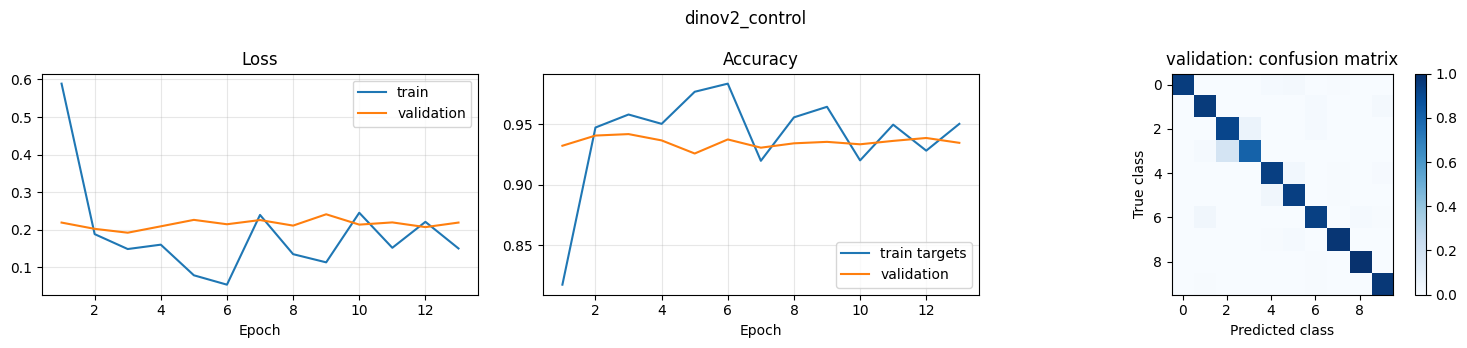

Pseudo-labels selected: 1000
dinov2_pseudo, epoch 1: accuracy=0.933
dinov2_pseudo, epoch 2: accuracy=0.941
Pseudo-labels selected: 1000
dinov2_pseudo, epoch 3: accuracy=0.934
dinov2_pseudo, epoch 4: accuracy=0.922


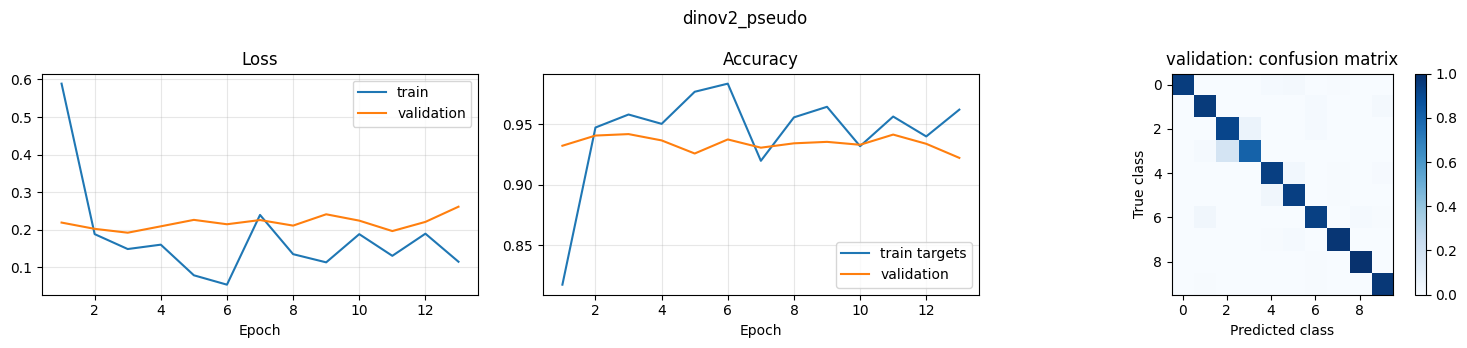

preprocessor_config.json:   0%|          | 0.00/352 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

convnextv2_base, epoch 1: accuracy=0.958
convnextv2_base, epoch 2: accuracy=0.962
convnextv2_base, epoch 3: accuracy=0.959
convnextv2_base, epoch 4: accuracy=0.961
convnextv2_base, epoch 5: accuracy=0.963
convnextv2_base, epoch 6: accuracy=0.961
convnextv2_base, epoch 7: accuracy=0.962
convnextv2_base, epoch 8: accuracy=0.963
convnextv2_base, epoch 9: accuracy=0.964
convnextv2_control, epoch 1: accuracy=0.964
convnextv2_control, epoch 2: accuracy=0.964
convnextv2_control, epoch 3: accuracy=0.967
convnextv2_control, epoch 4: accuracy=0.964


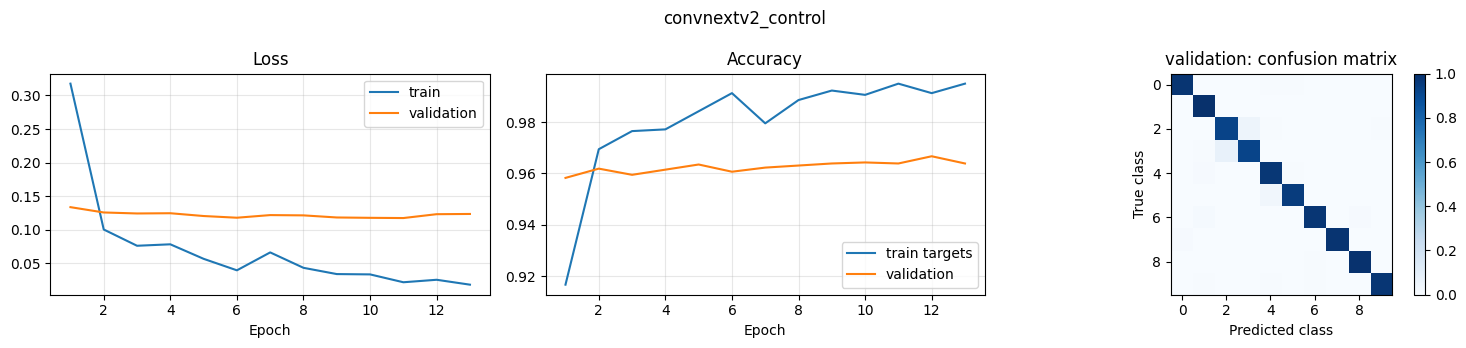

Pseudo-labels selected: 1000
convnextv2_pseudo, epoch 1: accuracy=0.963
convnextv2_pseudo, epoch 2: accuracy=0.960
Pseudo-labels selected: 1000
convnextv2_pseudo, epoch 3: accuracy=0.968
convnextv2_pseudo, epoch 4: accuracy=0.963


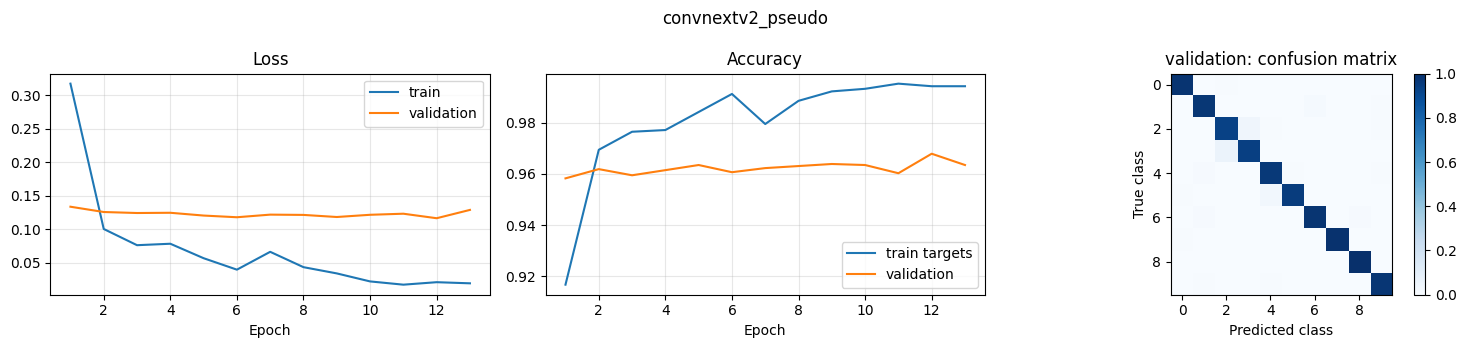

In [13]:
runs: dict = {}
results: list[dict] = []
for architecture in model_specs:
    set_seed(seed)
    model, image_mean, image_std = make_model(architecture)
    base_history, base_checkpoint = fit(
        model, f"{architecture}_base", training_stages, stage_epochs,
        image_mean, image_std,
    )
    for variant in ["control", "pseudo"]:
        restore_model(model, base_checkpoint)
        with_pseudo = variant == "pseudo"
        history, checkpoint = fit(
            model, f"{architecture}_{variant}", extra_stages, extra_epochs,
            image_mean, image_std, use_pseudo=with_pseudo,
        )
        history["epoch"] = history["epoch"] + len(base_history)
        full_history: pd.DataFrame = pd.concat(
            [base_history, history], ignore_index=True,
        )
        metrics = report(
            model, full_history, f"{architecture}_{variant}",
            image_mean, image_std,
        )
        runs[(architecture, variant)] = (full_history, checkpoint)
        results.append({
            "architecture": architecture, "variant": variant, **metrics,
        })
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

Сравниваем варианты по валидационной выборке и выбираем лучший для каждой архитектуры. Только после выбора один раз оцениваем модели на отложенной тестовой

,architecture,variant,loss,accuracy,macro_f1
0,dinov2,control,0.1923,0.9418,0.9371
1,dinov2,pseudo,0.1923,0.9418,0.9371
2,convnextv2,control,0.1233,0.9667,0.9646
3,convnextv2,pseudo,0.1166,0.9679,0.9664


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

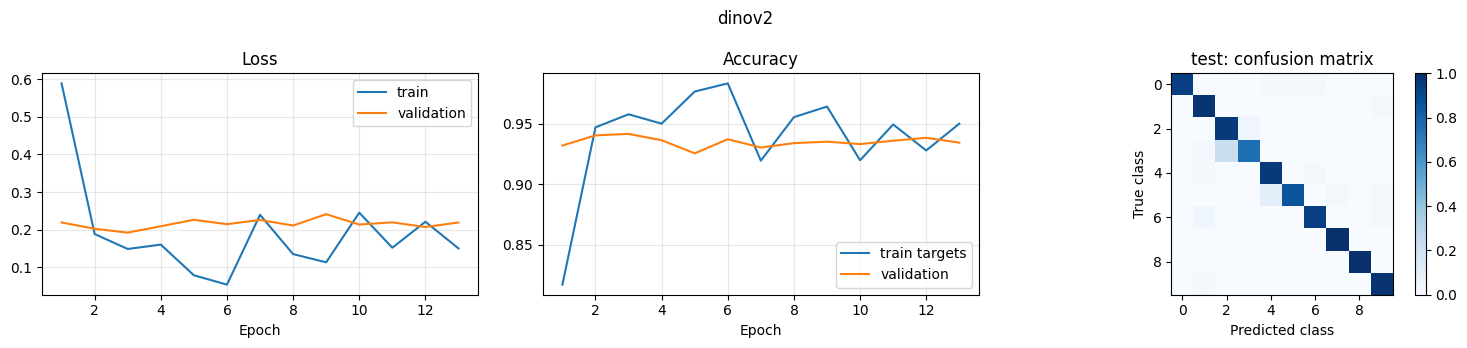

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

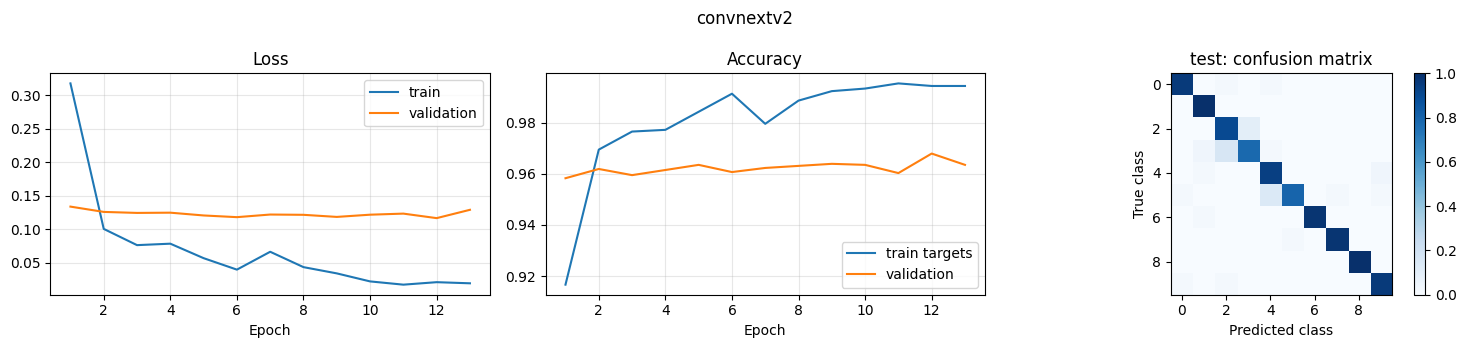

,architecture,loss,accuracy,macro_f1
0,dinov2,0.1992,0.938,0.9375
1,convnextv2,0.2066,0.930,0.9295


In [14]:
comparison: pd.DataFrame = pd.DataFrame(results)
display(comparison.round(4))
comparison.to_csv(output_dir / "validation.csv", index=False)
test_results: list[dict] = []
for architecture in model_specs:
    model_scores = comparison[comparison["architecture"] == architecture]
    best_index = model_scores["accuracy"].idxmax()
    best_variant = comparison.loc[best_index, "variant"]
    if comparison.loc[best_index, "accuracy"] < 0.60:
        raise RuntimeError(f"Check unexpectedly low accuracy: {architecture}")
    model, image_mean, image_std = make_model(architecture)
    history, checkpoint = runs[(architecture, best_variant)]
    restore_model(model, checkpoint)
    metrics = report(
        model, history, architecture, image_mean, image_std, split="test",
    )
    test_results.append({"architecture": architecture, **metrics})
    del model
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
test_table: pd.DataFrame = pd.DataFrame(test_results)
display(test_table.round(4))
test_table.to_csv(output_dir / "test.csv", index=False)

Рассчитываем фактическую разницу между псевдолейблингом и контрольным обучением

In [15]:
for architecture in model_specs:
    scores = comparison[comparison["architecture"] == architecture]
    scores = scores.set_index("variant")
    gain = scores.loc["pseudo", "accuracy"] - scores.loc["control", "accuracy"]
    print(f"{architecture}: pseudo vs control = {100 * gain:+.2f} pp")
print("Results:", output_dir)

dinov2: pseudo vs control = +0.00 pp
convnextv2: pseudo vs control = +0.12 pp
Results: /kaggle/working/hw1
